# Demo SVR: feature → validation → dự báo

Chạy SVR qua các cell quan sát được. Thuật toán và quy tắc chọn dùng lại source/config; không dùng dữ liệu test cho scaler hoặc chọn siêu tham số.

Chạy từ trên xuống bằng **Restart Kernel → Run All**, hoặc Shift+Enter từng cell. Thuật toán dùng lại từ `source/`; không sửa các CSV nghiên cứu đã có. Xem `notebooks/README.md` để cấu hình đường dẫn/kernel.

## Đường dẫn và môi trường
Kiểm tra các đường dẫn trước khi chạy. Các notebook độc lập: mặc định đọc clean/preparation đã lưu; không yêu cầu chạy notebook trước để có biến trong RAM.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p/'source/preprocessing').is_dir() and (p/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebooks directory.')
for folder in [PROJECT_ROOT, PROJECT_ROOT/'notebooks', PROJECT_ROOT/'source/preprocessing']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from demo_support import (configure, show_paths, demo_directory, save_table, save_json,
                          show_source, show_png, environment, compare_values, read_series, series_plot)
PATHS = configure(PROJECT_ROOT)
# Nếu cần, sửa PATHS.population_raw / history_raw / population_clean / history_clean / preparation tại đây.
show_paths(PATHS)
print('Python kernel:', sys.executable)


,setting,path,exists
0,project,D:\Phân tích kinh doanh_2627\GitHub\IS403.R14....,True
1,data_root,D:\Phân tích kinh doanh_2627,True
2,population_raw,D:\Phân tích kinh doanh_2627\archive\Electric_...,True
3,history_raw,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
4,population_clean,D:\Phân tích kinh doanh_2627\archive\EV_Popula...,True
5,history_clean,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
6,preparation,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True
7,output_root,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True


Python kernel: c:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe


In [2]:
OUT = demo_directory(PATHS, 'svr')
print('Output demo:', OUT)
display(environment())


Output demo: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\svr_20261116_040535_625c29ac


,package,version,status
0,pandas,3.0.5,Đã tìm thấy
1,numpy,2.5.3,Đã tìm thấy
2,scipy,1.18.1,Đã tìm thấy
3,matplotlib,3.11.2,Đã tìm thấy
4,statsmodels,0.15.0,Đã tìm thấy
5,scikit-learn,1.9.1,Đã tìm thấy
6,xgboost,3.4.1,Đã tìm thấy
7,ipykernel,7.3.0,Đã tìm thấy


## Chuỗi, train/test và cấu hình
Xem trước cấu hình và quy tắc chọn. Default chạy lại toàn bộ grid; không hard-code ID đã chọn.

In [3]:
from source.forecasting import features
from source.forecasting.models import ml, svr as model
from source.forecasting.backtest import run_cross_validation
from source.forecasting.run_ml_forecast import summarize_candidates, forecast_frame
from source.forecasting.metrics import calculate_metrics
series = read_series(PATHS)
train = series.loc[series['split'].eq('train')].copy()
test = series.loc[series['split'].eq('test')].copy()
spec = json.loads((PROJECT_ROOT/'source/forecasting/configs/svr.json').read_text(encoding='utf-8'))
display(pd.DataFrame(spec['candidates']))
print(spec['selection'])
show_source(model.fit)


,config_id,kernel,C,epsilon,gamma,tol,max_iter
0,SVR01,rbf,0.1,0.05,scale,0.001,-1
1,SVR02,rbf,0.1,0.10,scale,0.001,-1
2,SVR03,rbf,1.0,0.05,scale,0.001,-1
3,SVR04,rbf,1.0,0.10,scale,0.001,-1
4,SVR05,rbf,10.0,0.05,scale,0.001,-1
5,SVR06,rbf,10.0,0.10,scale,0.001,-1
6,SVR07,linear,1.0,0.10,scale,0.001,-1
7,SVR08,linear,10.0,0.10,scale,0.001,-1


Minimum mean validation RMSE; exact ties use config_id. No unspecified simplicity rule.


def fit(history, config):
    params = {key: value for key, value in config.items() if key != 'config_id'}
    return ml.fit(history, config, SVR(**params), scale_x=True)

## Tạo 5 feature từ quá khứ
Mẫu đầu ở tháng thứ 8. Full train 64 mẫu; ba prefix CV 40/46/52. Nhãn và rolling không chứa tương lai.

In [4]:
growth = features.compute_log_growth(train.ev_total)
X,y,names = features.build_supervised_dataset(growth)
supervised = pd.DataFrame(X, columns=names)
supervised.insert(0,'date',train.date.iloc[7:].to_numpy())
supervised['target_log_growth'] = y
display(supervised.head(8))
display(pd.DataFrame([{'train_months':n,'supervised_rows':len(features.build_supervised_dataset(features.compute_log_growth(train.ev_total.iloc[:n]))[1])}
                      for n in [47,53,59,71]]))
assert X.shape==(64,5)
# Căn chỉ số mẫu đầu: label r[7], đầu vào chỉ từ r[1:7].
expected_first = [growth[6],growth[5],growth[4],np.mean(growth[4:7]),np.mean(growth[1:7])]
compare_values('First-row past-only alignment',X[0],expected_first)


,date,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,target_log_growth
0,2017-08-31,0.022424,0.026505,0.025329,0.024753,0.026623,0.019365
1,2017-09-30,0.019365,0.022424,0.026505,0.022765,0.024767,0.023766
2,2017-10-31,0.023766,0.019365,0.022424,0.021852,0.024394,0.026138
3,2017-11-30,0.026138,0.023766,0.019365,0.023090,0.023921,0.020837
4,2017-12-31,0.020837,0.026138,0.023766,0.023580,0.023172,0.018834
5,2018-01-31,0.018834,0.020837,0.026138,0.021936,0.021894,0.032639
6,2018-02-28,0.032639,0.018834,0.020837,0.024103,0.023597,0.017998
7,2018-03-31,0.017998,0.032639,0.018834,0.023157,0.023369,0.024730


,train_months,supervised_rows
0,47,40
1,53,46
2,59,52
3,71,64


,check,passed,max_absolute_difference
0,First-row past-only alignment,True,0.0


## Validation chỉ trong train
True tính CV mới; False đọc lại bảng đã lưu và ghi rõ chế độ. Scaler của từng lượt fit nằm trong prefix.

In [5]:
RUN_GRID_SEARCH = True
if RUN_GRID_SEARCH:
    runs = [run_cross_validation(series,model.fit,model.forecast,config,return_forecasts=True) for config in spec['candidates']]
    cv = pd.concat([result[0] for result in runs],ignore_index=True)
    validation_forecasts = pd.concat([result[1] for result in runs],ignore_index=True)
    print('Validation recomputed from train prefixes.')
else:
    cv = pd.read_csv(PROJECT_ROOT/'results/forecasting/cv_svr.csv')
    validation_forecasts = pd.read_csv(PROJECT_ROOT/'results/forecasting/validation_forecasts_svr.csv')
    print('Showing saved validation; grid was NOT rerun in this cell.')
cv['n_supervised'] = cv['n_train_months'] - 7
display(cv[['config_id','fold','origin','rmse','status','warnings']])
scores, selected = summarize_candidates(cv,spec)
display(scores)
print('Locked config before test:',selected)


Validation recomputed from train prefixes.


,config_id,fold,origin,rmse,status,warnings
0,SVR01,1,2020-11-30,909.343973,ok,[]
1,SVR01,2,2021-05-31,1042.751456,ok,[]
2,SVR01,3,2021-11-30,824.531219,ok,[]
3,SVR02,1,2020-11-30,707.129077,ok,[]
4,SVR02,2,2021-05-31,930.654508,ok,[]
...,...,...,...,...,...,...
19,SVR07,2,2021-05-31,1647.363660,ok,[]
20,SVR07,3,2021-11-30,1339.678591,ok,[]
21,SVR08,1,2020-11-30,1983.326986,ok,[]
22,SVR08,2,2021-05-31,1647.109735,ok,[]


,config_id,kernel,C,epsilon,gamma,tol,...,selected,mean_rmse,mean_mae,mean_smape,mean_bias,within_tolerance
0,SVR01,rbf,0.1,0.05,scale,0.001,...,False,925.542216,814.940095,0.939927,293.234983,False
1,SVR02,rbf,0.1,0.10,scale,0.001,...,True,789.786364,702.975796,0.809077,231.992972,True
2,SVR03,rbf,1.0,0.05,scale,0.001,...,False,898.512612,763.693961,0.906890,608.924653,False
3,SVR04,rbf,1.0,0.10,scale,0.001,...,False,867.619001,746.772633,0.893772,503.708819,False
4,SVR05,rbf,10.0,0.05,scale,0.001,...,False,897.499512,774.425760,0.906918,564.954252,False
5,SVR06,rbf,10.0,0.10,scale,0.001,...,False,822.702743,710.572137,0.829631,499.445420,False
6,SVR07,linear,1.0,0.10,scale,0.001,...,False,1673.890510,1330.557925,1.546646,1296.342909,False
7,SVR08,linear,10.0,0.10,scale,0.001,...,False,1598.981442,1271.432986,1.485380,1224.814543,False


Locked config before test: {'config_id': 'SVR02', 'kernel': 'rbf', 'C': 0.1, 'epsilon': 0.1, 'gamma': 'scale', 'tol': 0.001, 'max_iter': -1}


## Minh họa scaler ở một prefix
Dùng fold 1 để nhìn thấy số mẫu và thống kê được fit từ prefix, không từ 83 tháng.

In [6]:
prefix = train.iloc[:47].copy()
fold_artifact = model.fit(prefix,selected)
X_fold,y_fold,_ = features.build_supervised_dataset(features.compute_log_growth(prefix.ev_total))
fold_info = ml.describe(fold_artifact)
display(pd.DataFrame([{'n_prefix_months':47,'n_supervised':fold_info['n_supervised'],
                       'target_mean':fold_info['target_mean'],'target_scale':fold_info['target_scale'],
                       'x_standardized':fold_info['x_standardized']}]))
compare_values('Prefix target scaler mean/std',[fold_info['target_mean'],fold_info['target_scale']],
               [y_fold.mean(),y_fold.std(ddof=0)])
if fold_artifact['x_scaler'] is not None:
    display(pd.DataFrame(fold_artifact['x_scaler'].transform(X_fold),columns=names).head())
else:
    display(pd.DataFrame(X_fold,columns=names).head())
    print('RF/XGBoost giữ nguyên X; chỉ nhãn tăng trưởng được chuẩn hóa.')


,n_prefix_months,n_supervised,target_mean,target_scale,x_standardized
0,47,40,0.022748,0.010272,True


,check,passed,max_absolute_difference
0,Prefix target scaler mean/std,True,0.0


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6
0,-0.027060,0.355290,0.212748,0.249318,0.530967
1,-0.324895,-0.041716,0.328507,-0.019321,0.229822
2,0.103622,-0.339249,-0.073334,-0.142699,0.169264
3,0.334587,0.088834,-0.374491,0.024585,0.092529
4,-0.181624,0.319564,0.058806,0.090858,-0.028974


## Fit cấu hình đã khóa trên full train
64 mẫu học. Xem estimator, scaler, warning và cỡ mô hình thực tế.

In [7]:
artifact = model.fit(train,selected)
assert artifact['converged'] is not False
fitted_info = ml.describe(artifact)
display(artifact['estimator'])
display(pd.DataFrame([fitted_info]))
if artifact['x_scaler'] is not None:
    display(pd.DataFrame(artifact['x_scaler'].transform(X),columns=names).head())
display(pd.DataFrame({'target_r':y,'standardized_z':artifact['y_scaler'].transform(y.reshape(-1,1)).ravel()}).head())


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


,n_supervised,feature_names,x_standardized,x_mean,x_scale,target_mean,...,target_variance,scaler_ddof,converged,warnings,n_support,support_fraction
0,64,"[r_lag_1, r_lag_2, r_lag_3, r_mean_3, r_mean_6]",True,"[0.023069589577328686, 0.022966458974048753, 0...","[0.008676142576108522, 0.00859508671488483, 0....",0.023211,...,0.000076,0,True,[],58,0.90625


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6
0,-0.074413,0.411698,0.259427,0.285751,0.693795
1,-0.426935,-0.063116,0.396817,-0.047566,0.326649
2,0.080264,-0.418963,-0.080111,-0.200648,0.252819
3,0.353636,0.093020,-0.437543,0.006912,0.159265
4,-0.257357,0.368970,0.076720,0.089140,0.011133


,target_r,standardized_z
0,0.019365,-0.440100
1,0.023766,0.063505
2,0.026138,0.334941
3,0.020837,-0.271724
4,0.018834,-0.500871


## Xem một bước dự báo và đổi ngược scaler
Tại gốc, đầu vào chỉ có tăng trưởng lịch sử. Không kẹp r âm về 0.

In [8]:
row = features.extract_features_at_step(growth)
z_one,r_one = ml.predict_growth(artifact,row)
level_one = float(train.ev_total.iloc[-1]*np.exp(r_one))
display(pd.DataFrame([dict(zip(names,row),z_pred=z_one,r_pred=r_one,pred=level_one)]))


,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,z_pred,r_pred,pred
0,0.031478,0.033105,0.016176,0.02692,0.026017,-0.099639,0.02234,115499.700988


## Dự báo đệ quy 12 bước và trace
Bước 2 dùng r_pred bước 1; actual test chỉ ghép vào sau khi sinh đủ 12 dự báo.

,check,passed,max_absolute_difference
0,Step 2 lag uses predicted growth,True,0.0


,date,r_lag_1,r_lag_2,r_lag_3,r_mean_3,r_mean_6,z_pred,r_pred,horizon,pred
0,2022-12-31,0.031478,0.033105,0.016176,0.026920,0.026017,-0.099639,0.022340,1,115499.700988
1,2023-01-31,0.022340,0.031478,0.033105,0.028975,0.026103,0.117279,0.024236,2,118333.130674
2,2023-02-28,0.024236,0.022340,0.031478,0.026018,0.025604,0.244431,0.025347,3,121370.845255
3,2023-03-31,0.025347,0.024236,0.022340,0.023974,0.025447,0.027396,0.023450,4,124250.680600
4,2023-04-30,0.023450,0.025347,0.024236,0.024344,0.026659,0.070195,0.023824,5,127246.426364
5,2023-05-31,0.023824,0.023450,0.025347,0.024207,0.025113,0.114354,0.024210,6,130364.694091
6,2023-06-30,0.024210,0.023824,0.023450,0.023828,0.023901,0.051206,0.023658,7,133485.700777
7,2023-07-31,0.023658,0.024210,0.023824,0.023898,0.024121,0.060939,0.023744,8,136693.051282
8,2023-08-31,0.023744,0.023658,0.024210,0.023871,0.024039,0.076003,0.023875,9,139995.892662
9,2023-09-30,0.023875,0.023744,0.023658,0.023759,0.023794,0.057806,0.023716,10,143355.743018


,date,actual,pred
0,2022-12-31,115665.0,115499.700988
1,2023-01-31,119377.0,118333.130674
2,2023-02-28,122322.0,121370.845255
3,2023-03-31,125478.0,124250.680600
4,2023-04-30,129728.0,127246.426364
5,2023-05-31,133975.0,130364.694091
6,2023-06-30,138353.0,133485.700777
7,2023-07-31,142537.0,136693.051282
8,2023-08-31,148730.0,139995.892662
9,2023-09-30,152690.0,143355.743018


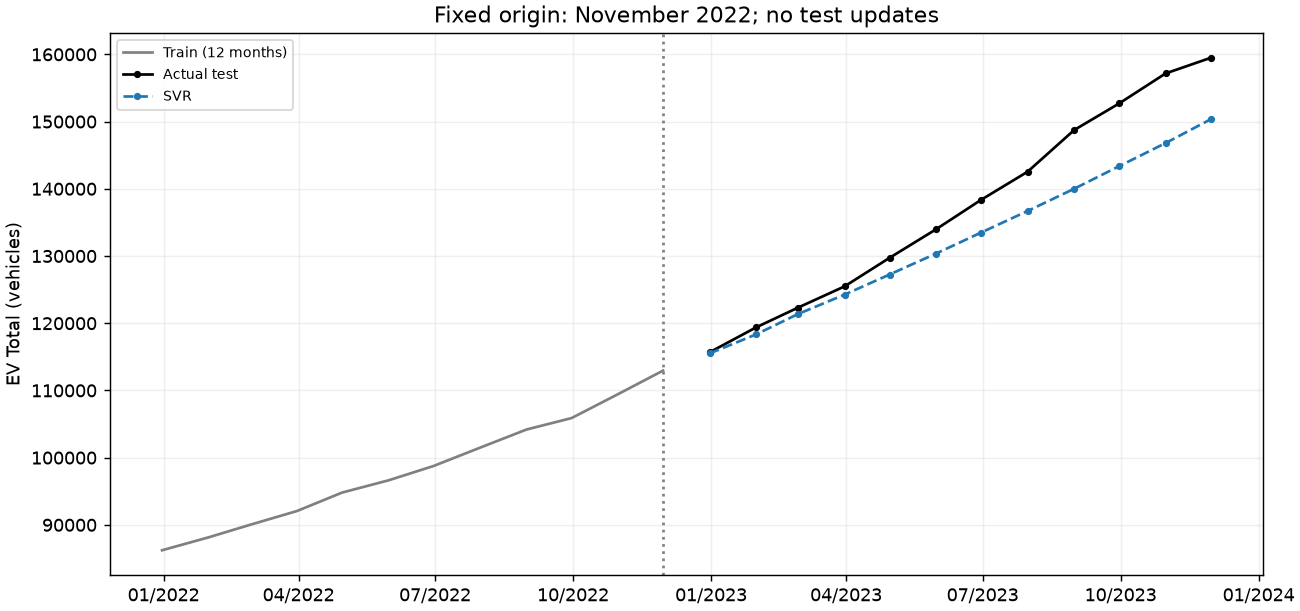

In [9]:
pred, rows = ml.forecast_with_trace(artifact,train,12)
trace = pd.DataFrame(rows)
trace.insert(0,'date',test.date.dt.strftime('%Y-%m-%d').to_numpy())
compare_values('Step 2 lag uses predicted growth',trace.loc[1,'r_lag_1'],trace.loc[0,'r_pred'])
forecast = forecast_frame('svr',selected['config_id'],test,pred)
display(trace)
display(forecast[['date','actual','pred']])
series_plot(train,test,{'SVR':pred})


## Chấm điểm và đối chiếu dự báo
Không dùng test để chọn lại config. Khoảng dự báo ML chưa được ước lượng, giữ trống.

In [10]:
metric = calculate_metrics(test.ev_total,pred)
display(pd.DataFrame([dict(model='SVR',**metric)]))
reference = pd.read_csv(PROJECT_ROOT/'results/forecasting/forecast_svr.csv')
compare_values('SVR forecast vs published result',pred,reference.pred)
assert forecast[['lower_95','upper_95','interval_level']].isna().all().all()
save_table(forecast,OUT/'forecast_svr.csv')
save_table(trace,OUT/'trace_svr.csv')
save_table(scores,OUT/'candidate_scores_svr.csv')
save_table(cv,OUT/'cv_svr.csv')
save_table(validation_forecasts,OUT/'validation_forecasts_svr.csv')
save_json({'config':selected,'fit':fitted_info,'test_metrics':metric},OUT/'demo_fit.json')


,model,rmse,mae,smape,bias
0,SVR,6020.980986,4814.062233,3.357829,4814.062233


,check,passed,max_absolute_difference
0,SVR forecast vs published result,True,1.455192e-11


## Giới hạn diễn giải
Một gốc test 12 tháng không chứng minh ưu thế dài hạn. Các fold CV chồng lấn, không coi là mẫu độc lập. Nếu môi trường/dữ liệu đổi và kết quả lệch, giữ kết quả thật và kiểm tra nguyên nhân; không sửa số cho giống bảng cũ.